# MetaFL — run all formal analysis steps

Runs MwC 01–05 and then Main 01–10 in one kernel. The formal universe is 12 cortical + 14 limbic ROIs and 168 cross-network edges.


In [1]:
from pathlib import Path
import os

_repo = Path(os.environ.get("METAFL_ROOT", Path.cwd())).resolve()
if not (_repo / "pipeline_steps").is_dir() and (_repo.parent / "pipeline_steps").is_dir():
    _repo = _repo.parent
if not (_repo / "pipeline_steps").is_dir():
    raise FileNotFoundError("Set METAFL_ROOT to the repository root")
os.environ["METAFL_ROOT"] = str(_repo)
os.chdir(_repo)

def _run_step(relative_path):
    _path = _repo / "pipeline_steps" / relative_path
    _code = compile(_path.read_text(encoding="utf-8"), str(_path), "exec")
    exec(_code, get_ipython().user_ns)


## MwC pipeline


### MwC 01 — setup and AAL3-144 recomputation

Recompute MwC across all 144 retained AAL3 nodes before extracting the formal 26 targets.


In [2]:
_run_step("mwc_01_setup_recompute.py")


,input,size_kib
0,03_compute_normative_sc_mwc.py,12.4
1,session_gcmi_pet_AAL3_144.npz,19663.6
2,normative_SC_top10_mask.npz,53.7
3,subject_level_corticolimbic26_normativeSC10_Mw...,139.7
4,subject_level_AAL3_144_normativeSC10_MwC_wide....,333.6
5,validation_report.json,0.2
6,corticolimbic_12x14_ROI_definition.csv,0.6
7,clinical_data.xlsx,12.6
8,subject_level_corticolimbic26_age_sex_adjusted...,154.9


{
  "full_144": "./outputs/mwc/recomputed_normative_sc/subject_level_AAL3_144_normativeSC10_MwC_wide.csv.gz",
  "selected_26": "./outputs/mwc/recomputed_normative_sc/subject_level_corticolimbic26_normativeSC10_MwC_wide.csv",
  "validation": "./outputs/mwc/recomputed_normative_sc/calculation_validation_report.json"
}
PASS: AAL3-144 normative-SC-constrained MwC recomputed before 26-ROI extraction


,check,passed
0,sessions_291,True
1,retained_AAL3_nodes_144,True
2,fixed_dTOR_normative_SC_edges_1030,True
3,gcmi_floor_bits_0p01,True
4,row_normalization_error_below_1e_12,True
5,all_144_nodes_computed_before_26_extraction,True
6,isolated_nodes_remain_missing,True
7,full_144_matches_validated_reference,True
8,selected_26_matches_validated_reference,True


### MwC 02 — subject-level 26-ROI extraction

Extract and export the 12-cortical + 14-limbic subject-level MwC values.


In [3]:
_run_step("mwc_02_subject_level.py")


,quantity,value
0,upstream paired sessions,291.0
1,clinical sessions,291.0
2,ROIs per session,26.0
3,long-table rows,7566.0
4,all-144 to 26 extraction maximum absolute error,0.0


,node_index,network,AAL3_ID,ROI
0,1,cortical,3,Frontal_Sup_2_L
1,2,cortical,4,Frontal_Sup_2_R
2,3,cortical,5,Frontal_Mid_2_L
3,4,cortical,6,Frontal_Mid_2_R
4,5,cortical,19,Frontal_Sup_Medial_L
5,6,cortical,20,Frontal_Sup_Medial_R
6,7,cortical,21,Frontal_Med_Orb_L
7,8,cortical,22,Frontal_Med_Orb_R
8,9,cortical,25,OFCmed_L
9,10,cortical,26,OFCmed_R


### MwC 03 — deviation maps and spatial replication

Create the formal 26-ROI age/sex-adjusted MwC deviation heatmap and TRD1–TRD2 replication result.


,n_ROIs,cortical_ROIs,limbic_ROIs,TRD1_n,TRD2_n,pearson_r,pearson_p_two_sided,same_direction_agreement,DSC_weighted,MwC_input
0,26,12,14,35,104,0.970751,0.0,0.923077,0.819914,HC-only age/sex residual z scores; 26 ROIs ext...


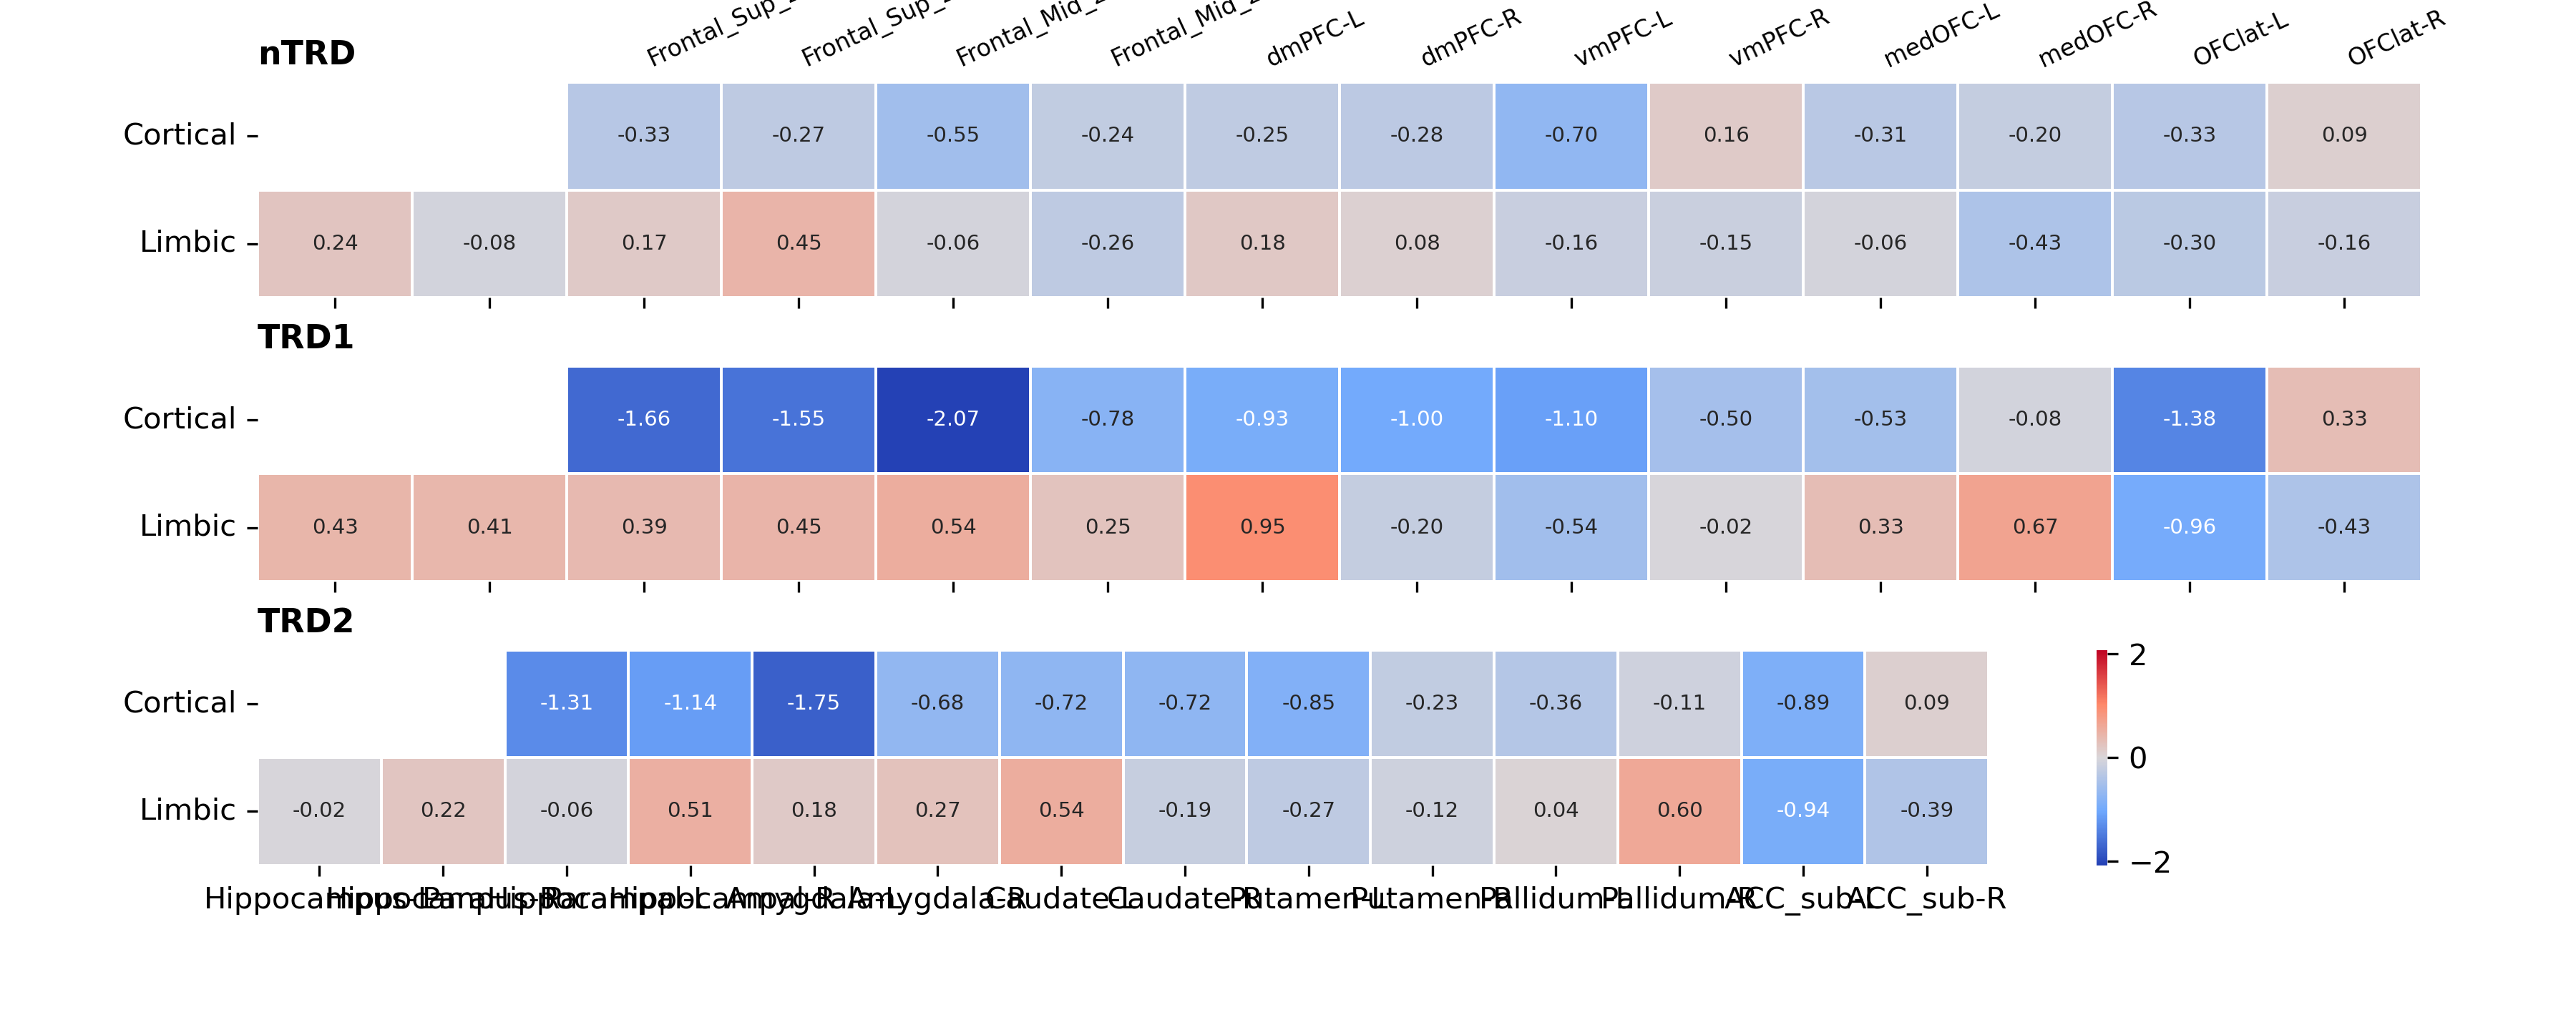

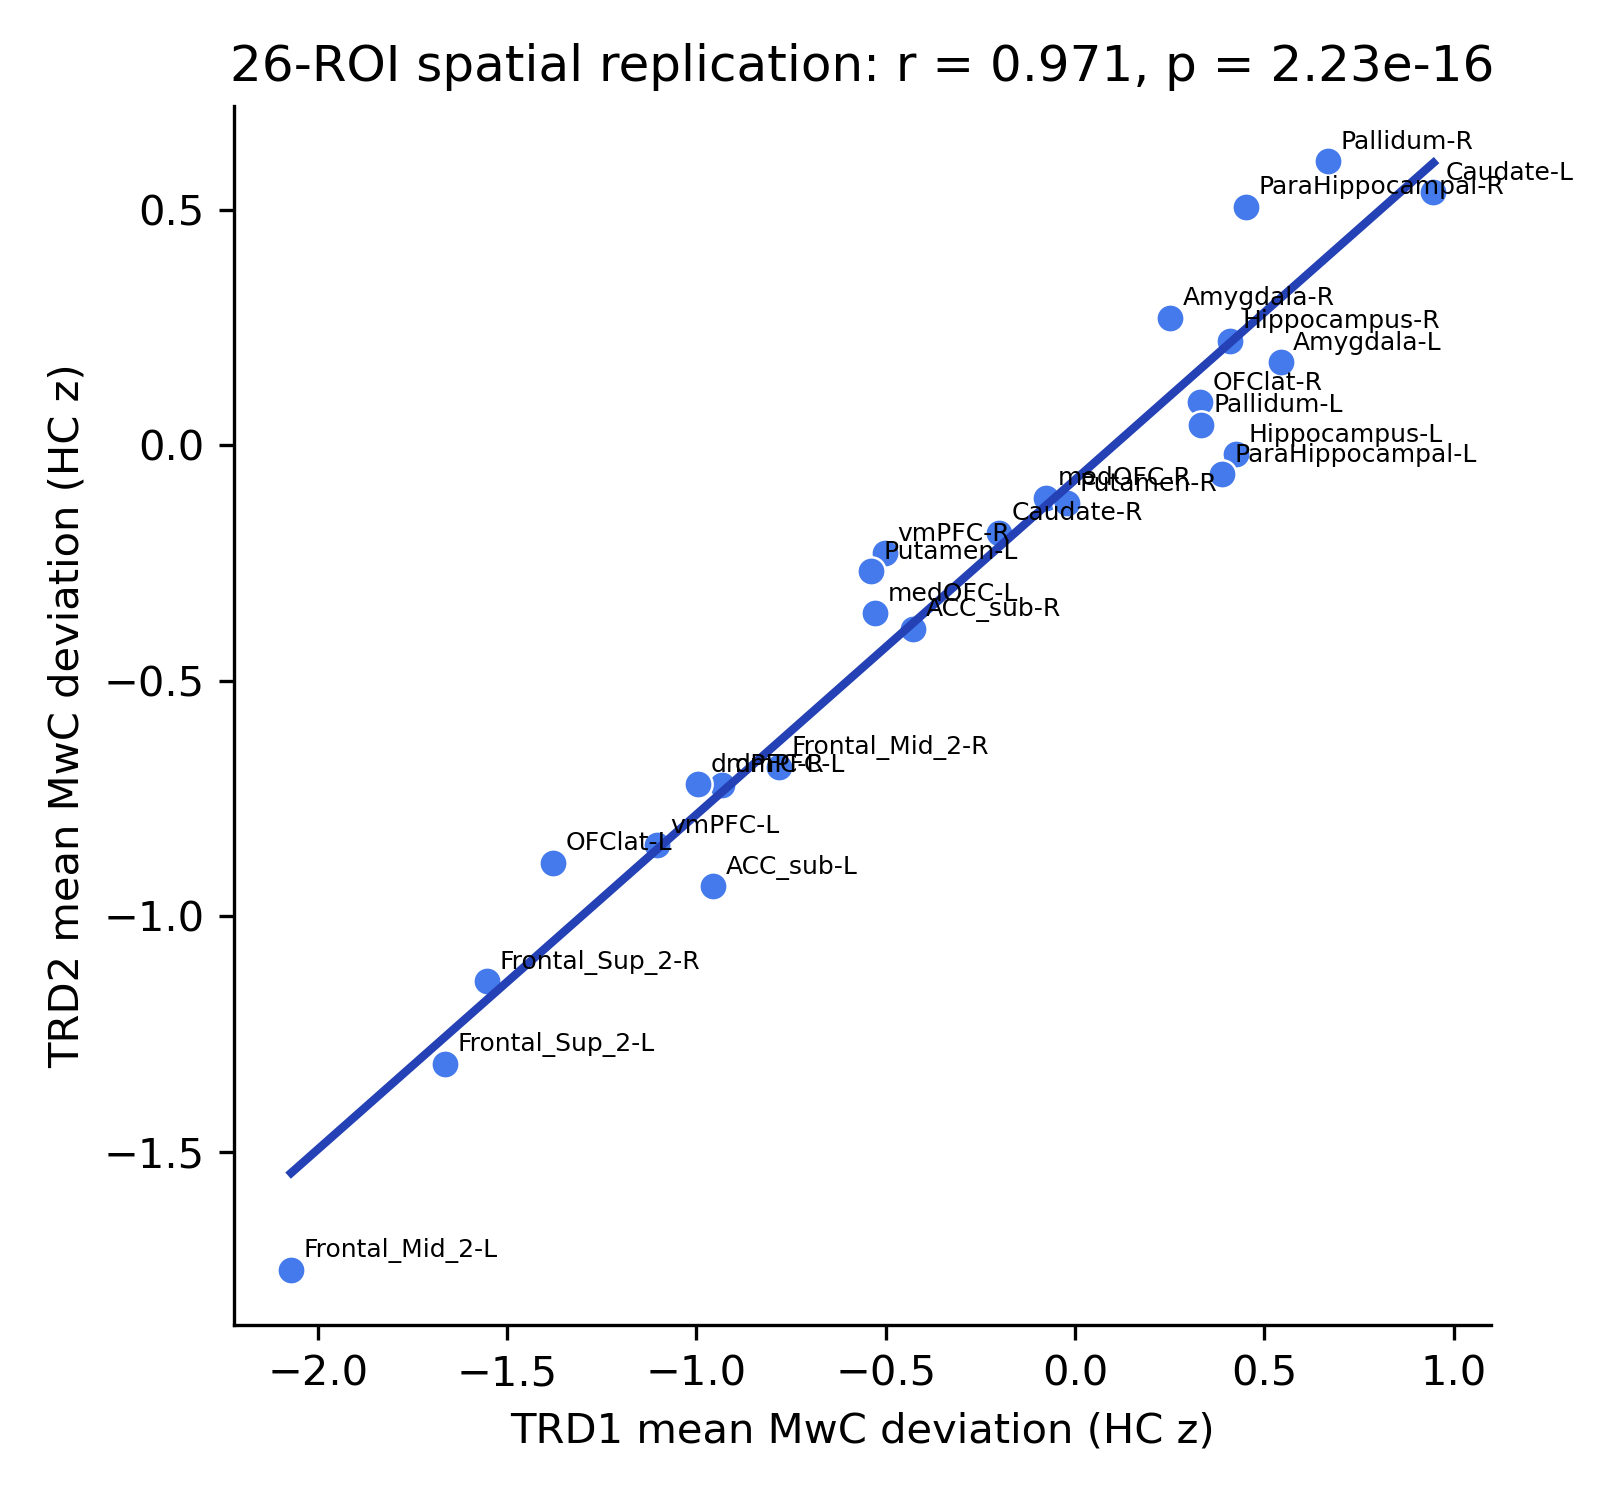

In [4]:
_run_step("mwc_03_deviation_spatial.py")


### MwC 04 — nTRD versus TRD analysis

Test the selected MwC deviations using the formal 26-ROI age/sex-adjusted data.


In [5]:
_run_step("mwc_04_group_analysis.py")


,region,metric,comparison,covariates,n_nTRD,n_TRD,nTRD_mean_HC_z,nTRD_sd_HC_z,TRD_mean_HC_z,TRD_sd_HC_z,beta_TRD_minus_nTRD_HC_SD,hc3_se,ci95_low_TRD_minus_nTRD_HC_SD,ci95_high_TRD_minus_nTRD_HC_SD,p_adjusted
0,SFG_L,MwC_deviation_Frontal_Sup_2_L,TRD - nTRD,age + sex,25,35,-0.330766,1.225849,-1.663635,1.989599,-1.237044,0.394293,-2.009844,-0.464244,0.001705
1,MFG_L,MwC_deviation_Frontal_Mid_2_L,TRD - nTRD,age + sex,25,35,-0.547601,1.663094,-2.070576,1.973155,-1.469070,0.426474,-2.304944,-0.633195,0.000572
2,vmPFC_R,MwC_deviation_Frontal_Med_Orb_R,TRD - nTRD,age + sex,25,35,0.157078,1.420818,-0.502719,1.116825,-0.767800,0.366137,-1.485416,-0.050184,0.035991
3,PAL_L,MwC_deviation_Pallidum_L,TRD - nTRD,age + sex,25,34,-0.056145,1.195773,0.333766,1.180415,0.570440,0.286103,0.009688,1.131192,0.046171
4,HPC_R,MwC_deviation_Hippocampus_R,TRD - nTRD,age + sex,25,35,-0.076973,0.901990,0.409947,0.986862,0.582871,0.236208,0.119912,1.045830,0.013601
5,AMY_R,MwC_deviation_Amygdala_R,TRD - nTRD,age + sex,25,35,-0.263747,0.985869,0.251930,0.782117,0.477820,0.218350,0.049862,0.905777,0.028646


### MwC 05 — figures and audit

Create the selected MwC raincloud figure and audit the five-step MwC workflow.


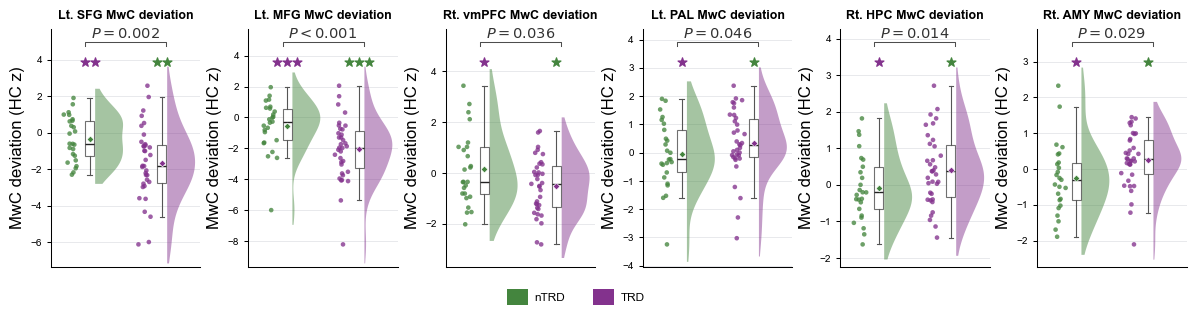

Wrote:
 - ./outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.png
 - ./outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.pdf
 - ./outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.svg
MwC scope audit passed: 16 normative-SC MwC files.


In [6]:
_run_step("mwc_05_figures_audit.py")


## Main pipeline


### Main 01 — setup, input loading, and validation

Load the formal 12-cortical + 14-limbic ROI definition, clinical/PET inputs, 26-node MwC data, and validate 168 cross-network edges.


In [7]:
_run_step("main_01_setup_load.py")


MetaFL package root: .
Main-analysis output root: ./outputs/main_analyses
Cortical IDs: [3, 4, 5, 6, 19, 20, 21, 22, 25, 26, 31, 32]
Limbic IDs: [41, 42, 43, 44, 45, 46, 75, 76, 77, 78, 79, 80, 151, 152]
Cross-edge family: 168


,cohort,clinical_n,ses01_complete_n
0,HC,23,23
1,nTRD,25,25
2,TRD1,35,35
3,TRD2,104,104


,cohort,baseline_n,metric
0,nTRD,25,age/sex-adjusted normative-SC MwC deviation z
1,TRD1,35,age/sex-adjusted normative-SC MwC deviation z
2,TRD2,104,age/sex-adjusted normative-SC MwC deviation z


### Main 02 — demographics and HC reference

Build the HC references and subject-level regional SUVR and 12×14 metabolic-connectivity deviations.


In [8]:
_run_step("main_02_demographics_hc_reference.py")


Written: ./outputs/main_analyses/demographic_and_clinical_summary.xlsx


,variable,HC,nTRD,TRD1,TRD2,primary_test,primary_p_value,TRD1_vs_TRD2_test,TRD1_vs_TRD2_p_value
0,Age,50.91 (17.04); n=23,52.32 (12.22); n=25,48.20 (15.52); n=35,39.09 (13.96); n=104,"one-way ANOVA: HC, nTRD, TRD1",0.561396,Welch t-test,0.003261
1,"Female, n (%)",14 (60.87%); n=23,14 (56.00%); n=25,25 (71.43%); n=35,73 (70.19%); n=104,"Pearson chi-square: HC, nTRD, TRD1",0.443311,Fisher exact test,1.000000
2,Education,14.17 (3.46); n=23,13.44 (3.86); n=25,13.14 (3.83); n=35,14.57 (2.81); n=104,"one-way ANOVA: HC, nTRD, TRD1",0.587829,Welch t-test,0.048544


,variable,nTRD,TRD1,TRD2,primary_test,primary_p_value,TRD1_vs_TRD2_test,TRD1_vs_TRD2_p_value
0,Baseline HDRS-17,3.72 (3.22); n=25,15.89 (7.38); n=35,22.84 (5.11); n=104,Welch t-test: nTRD versus TRD1,1.726193e-11,Welch t-test,0.000005


,variable,note
0,MSM scores,Not required for the released analyses


,variable,iTBS,rTMS,sham,test,statistic,df_1,df_2,p_value
0,HDRS reduction (baseline - post),6.73 (8.20); n=37,7.65 (6.95); n=34,6.06 (4.94); n=33,ordinary one-way ANOVA,0.448348,2,101,0.639948


,variable,rTMS,iTBS,sham,test,p_value
0,"Age, years",39.35 (11.79); n=34,37.95 (14.52); n=37,40.09 (15.62); n=33,one-way ANOVA,0.809492
1,"Female, n (%)",23 (67.65%); n=34,27 (72.97%); n=37,23 (69.70%); n=33,Pearson chi-square,0.884317
2,"Education, years",14.53 (2.60); n=34,14.27 (2.59); n=37,14.94 (3.27); n=33,one-way ANOVA,0.611602
3,Baseline HDRS-17,22.74 (4.69); n=34,23.41 (5.53); n=37,22.30 (5.12); n=33,one-way ANOVA,0.663926
4,HDRS-17 reduction,7.65 (6.95); n=34,6.73 (8.20); n=37,6.06 (4.94); n=33,one-way ANOVA,0.639948


### Main 03 — baseline discovery and sensitivity

Run nTRD-versus-TRD baseline regional, connectivity, MwC, and baseline-severity sensitivity analyses.


In [9]:
_run_step("main_03_baseline_discovery_sensitivity.py")


,modality,tested_n,primary_p_lt_0p01,HDRS_adjusted_p_lt_0p01,retained,lost,new
0,edge,168,22,2,2,20,0
1,regional,26,7,2,2,5,0
2,MwC,26,2,1,0,2,1


TRD2 subject-level deviations: (104, 168) (104, 26)


### Main 04 — longitudinal paired and clinical analyses

Run iTBS, rTMS, and sham paired analyses plus prespecified clinical correlations.


In [10]:
_run_step("main_04_longitudinal_paired_clinical.py")


Longitudinal edge archive: ./outputs/main_analyses/02_TRD2_deviation_prepost_agesex/longitudinal_high_quality_PET_subject_matrices_cross168.npz


,arm,n,edge_prepost_uncorrected_p_lt_0p05,edge_HDRS_FDR_q_lt_0p05_primary,edge_HDRS_uncorrected_p_lt_0p05_exploratory,regional_prepost_uncorrected_p_lt_0p05,regional_HDRS_FDR_q_lt_0p05_primary,regional_HDRS_uncorrected_p_lt_0p05_exploratory
0,iTBS,37,12,0,0,0,0,0
1,rTMS,34,10,0,1,0,0,0
2,sham,33,7,0,0,8,0,0


### Main 05 — group-by-time and MwC analyses

Run group-by-time models and the formal 26-ROI age/sex-adjusted MwC analysis.


In [11]:
_run_step("main_05_interactions_mwc.py")


,active_arm,modality,ROI_1,ROI_2,active_n,active_pre_mean_deviation,active_post_mean_deviation,active_post_minus_pre,active_change_CI95_low,active_change_CI95_high,active_Cohen_dz,active_paired_t,active_paired_p_uncorrected,sham_n,sham_pre_mean_deviation,sham_post_mean_deviation,sham_post_minus_pre,sham_change_CI95_low,sham_change_CI95_high,sham_Cohen_dz,sham_paired_t,sham_paired_p_uncorrected,interaction_beta_active_minus_sham,interaction_CI95_low,interaction_CI95_high,interaction_t,interaction_effect_size_partial_r,interaction_df_resid,interaction_p_uncorrected,interaction_n,interaction_residual_shapiro_W_descriptive,interaction_residual_shapiro_p_descriptive,interaction_breusch_pagan_p_descriptive,interaction_q_fdr_BH_within_arm_modality
0,iTBS,edge,AAL3_031_OFClat_L,AAL3_151_ACC_sub_L,37,0.322443,-0.025557,-0.348000,-0.572619,-0.123381,-0.516559,-3.142105,0.003349,33,0.006111,0.071019,0.064908,-0.181350,0.311167,0.093460,0.536889,0.595058,-0.416926,-0.743816,-0.090037,-2.546487,-0.299102,66.0,0.013222,70,0.959085,2.229230e-02,0.955781,0.158664
1,iTBS,edge,AAL3_032_OFClat_R,AAL3_151_ACC_sub_L,37,0.143246,-0.094722,-0.237968,-0.449205,-0.026731,-0.375609,-2.284743,0.028325,33,-0.006331,0.048966,0.055297,-0.219219,0.329812,0.071425,0.410306,0.684316,-0.301989,-0.643107,0.039130,-1.767539,-0.212595,66.0,0.081760,70,0.967031,6.190867e-02,0.543463,0.268396
2,iTBS,edge,AAL3_020_Frontal_Sup_Medial_R,AAL3_151_ACC_sub_L,37,-0.674562,-1.149253,-0.474690,-0.944425,-0.004956,-0.336934,-2.049492,0.047754,33,-1.759151,-1.456476,0.302674,-0.587304,1.192653,0.120591,0.692745,0.493467,-0.833538,-1.788543,0.121467,-1.742621,-0.209731,66.0,0.086058,70,0.860085,1.418239e-06,0.145837,0.268396
3,iTBS,edge,AAL3_020_Frontal_Sup_Medial_R,AAL3_079_Pallidum_L,37,-0.044957,0.487212,0.532169,0.024216,1.040121,0.349312,2.124782,0.040539,33,-0.419213,-0.502274,-0.083060,-0.671197,0.505076,-0.050077,-0.287668,0.775455,0.657133,-0.104078,1.418344,1.723581,0.207539,66.0,0.089465,70,0.952066,9.315697e-03,0.435947,0.268396
4,iTBS,edge,AAL3_032_OFClat_R,AAL3_041_Hippocampus_L,37,-0.215137,-0.469763,-0.254626,-0.486144,-0.023107,-0.366694,-2.230514,0.032036,33,-0.626612,-0.479683,0.146929,-0.351627,0.645484,0.104499,0.600302,0.552533,-0.415261,-0.942064,0.111542,-1.573824,-0.190188,66.0,0.120310,70,0.751504,1.501874e-09,0.219319,0.288744
5,iTBS,edge,AAL3_031_OFClat_L,AAL3_041_Hippocampus_L,37,-0.129263,-0.393839,-0.264576,-0.449840,-0.079312,-0.476153,-2.896328,0.006384,33,-0.423395,-0.437227,-0.013833,-0.374408,0.346743,-0.013603,-0.078142,0.938201,-0.269393,-0.654498,0.115712,-1.396658,-0.169431,66.0,0.167195,70,0.874886,4.515369e-06,0.238554,0.307427
6,iTBS,edge,AAL3_021_Frontal_Med_Orb_L,AAL3_079_Pallidum_L,37,-0.543471,-0.091971,0.451500,0.006287,0.896713,0.338125,2.056733,0.047014,33,-0.978725,-1.088196,-0.109471,-0.840356,0.621414,-0.053109,-0.305090,0.762273,0.566761,-0.266979,1.400502,1.357227,0.164779,66.0,0.179332,70,0.959309,2.293528e-02,0.187619,0.307427
7,iTBS,edge,AAL3_022_Frontal_Med_Orb_R,AAL3_151_ACC_sub_L,37,-1.163232,-2.042845,-0.879613,-1.693157,-0.066070,-0.360494,-2.192800,0.034867,33,-1.740244,-1.893031,-0.152787,-1.138210,0.832636,-0.054977,-0.315821,0.754189,-0.784864,-2.037172,0.467445,-1.251314,-0.152231,66.0,0.215237,70,0.954095,1.194855e-02,0.774049,0.322856
8,iTBS,edge,AAL3_019_Frontal_Sup_Medial_L,AAL3_079_Pallidum_L,37,-0.636765,-0.061021,0.575744,0.159609,0.991879,0.461299,2.805974,0.008043,33,-1.641953,-1.391368,0.250585,-0.473564,0.974734,0.122701,0.704863,0.485995,0.335120,-0.474447,1.144688,0.826478,0.101210,66.0,0.411511,70,0.889393,1.515305e-05,0.193075,0.542308
9,iTBS,edge,AAL3_021_Frontal_Med_Orb_L,AAL3_151_ACC_sub_L,37,-0.521271,-0.986941,-0.465670,-0.868422,-0.062919,-0.385503,-2.344926,0.024663,33,-0.580279,-0.826237,-0.245958,-0.753809,0.261892,-0.171730,-0.986512,0.331283,-0.240181,-0.873904,0.393542,-0.756699,-0.092742,66.0,0.451923,70,0.981972,4.104783e-01,0.689290,0.542308


                      analysis  arm                       family  tested  nominal_p_lt_0p05  fdr_q_lt_0p05                                                                                         method
         baseline TRD1 vs nTRD TRD1               26 MwC targets      26                  8              0                                                                             HC3 OLS; age + sex
               paired pre-post iTBS               26 MwC targets      26                  0              0                                                                       paired t; post minus pre
               paired pre-post rTMS               26 MwC targets      26                  0              0                                                                       paired t; post minus pre
               paired pre-post sham               26 MwC targets      26                 10              3                                                                       paired t; post 

,modality


,modality,arm,paired_node_index,paired_network,paired_AAL3_ID,ROI,display_roi,paired_n_paired,paired_pre_mean_deviation_HC_z,paired_pre_SD_deviation_HC_z,paired_post_mean_deviation_HC_z,paired_post_SD_deviation_HC_z,paired_post_minus_pre_HC_z,paired_change_ci95_low,paired_change_ci95_high,paired_paired_t,paired_paired_df,paired_effect_size_Cohen_dz,paired_paired_p_uncorrected,paired_change_shapiro_W,...,interaction_covariates,interaction_model,interaction_interaction_q_fdr_BH_26_nodes,interaction_interaction_nominal_p_lt_0p05,interaction_interaction_fdr_q_lt_0p05,HDRS_node_index,HDRS_network,HDRS_AAL3_ID,HDRS_n_used,HDRS_HDRS_improvement_definition,HDRS_MwC_change_definition,HDRS_partial_Spearman_r,HDRS_partial_Spearman_p_uncorrected,HDRS_covariates,HDRS_paired_p_uncorrected,HDRS_paired_nominal_p_lt_0p05,HDRS_partial_Spearman_q_fdr_BH_26_nodes,HDRS_HDRS_nominal_p_lt_0p05,HDRS_HDRS_fdr_q_lt_0p05,HDRS_paired_and_HDRS_nominal_p_lt_0p05


### Main 06 — spatial replication

Quantify TRD1–TRD2 spatial replication for 26 regional, 168 connectivity, and 26 MwC features.


In [12]:
_run_step("main_06_spatial_replication_report.py")


,modality,display_name,n_TRD1,n_TRD2,n_features,metric,estimate,parametric_p_descriptive,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,same_direction_count,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Regional SUVR,35,104,26,Pearson correlation,0.973450,7.072936e-17,9.999900e-06,0.007145,0.468580,0.468581,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
1,Regional,Regional SUVR,35,104,26,Same-direction proportion,0.961538,NaN,9.999900e-05,0.505726,0.730769,0.807692,>=,True,True,25.0,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
2,Regional,Regional SUVR,35,104,26,Magnitude-weighted signed DSC,0.706271,NaN,9.999900e-06,0.295898,0.467967,0.467969,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
3,Connectivity,Metabolic edge,35,104,168,Pearson correlation,0.800049,1.127070e-38,5.511464e-07,0.070418,0.283198,0.283198,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
4,Connectivity,Metabolic edge,35,104,168,Same-direction proportion,0.910714,NaN,5.522487e-04,0.838435,0.875000,0.886905,>=,True,True,153.0,3628800,True,NaN,Exact independent permutations of six bilatera...
5,Connectivity,Metabolic edge,35,104,168,Magnitude-weighted signed DSC,0.761419,NaN,5.511464e-07,0.589102,0.635419,0.635419,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
6,MwC,MwC,35,104,26,Pearson correlation,0.970751,2.228946e-16,9.999900e-06,0.059244,0.453000,0.453006,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
7,MwC,MwC,35,104,26,Same-direction proportion,0.923077,NaN,4.999950e-05,0.544065,0.692308,0.769231,>=,True,True,24.0,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
8,MwC,MwC,35,104,26,Magnitude-weighted signed DSC,0.814744,NaN,9.999900e-06,0.362865,0.514438,0.514438,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...


,modality,metric,estimate,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,critical_same_direction_count,critical_same_direction_percent,n_features,alpha,alternative,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Same-direction proportion,0.961538,9.999900e-05,0.505726,0.730769,0.807692,>=,True,True,21.0,80.769231,26,0.05,greater,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
1,Regional,Magnitude-weighted signed DSC,0.706271,9.999900e-06,0.295898,0.467967,0.467969,>=,True,True,NaN,NaN,26,0.05,greater,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
2,Connectivity,Same-direction proportion,0.910714,5.522487e-04,0.838435,0.875000,0.886905,>=,True,True,149.0,88.690476,168,0.05,greater,3628800,True,NaN,Exact independent permutations of six bilatera...
3,Connectivity,Magnitude-weighted signed DSC,0.761419,5.511464e-07,0.589102,0.635419,0.635419,>=,True,True,NaN,NaN,168,0.05,greater,3628800,True,NaN,Exact independent permutations of six bilatera...
4,MwC,Same-direction proportion,0.923077,4.999950e-05,0.544065,0.692308,0.769231,>=,True,True,20.0,76.923077,26,0.05,greater,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
5,MwC,Magnitude-weighted signed DSC,0.814744,9.999900e-06,0.362865,0.514438,0.514438,>=,True,True,NaN,NaN,26,0.05,greater,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...


Combined workbook: ./outputs/main_analyses/all_reported_results.xlsx


,analysis,family_or_tested_n,reporting_rule,reported_n
0,TRD1 vs nTRD edge,168,uncorrected p<0.01,22
1,TRD1 vs nTRD regional,26,uncorrected p<0.01,7
2,HDRS-adjusted sensitivity edge,168,uncorrected p<0.01,2
3,HDRS-adjusted sensitivity regional,26,uncorrected p<0.01,2
4,iTBS edge pre-post,168,paired uncorrected p<0.05,12
5,iTBS edge HDRS,12,BH-FDR q<0.05 primary,0
6,iTBS edge HDRS,12,uncorrected p<0.05 exploratory,0
7,iTBS regional pre-post,26,paired uncorrected p<0.05,0
8,iTBS regional HDRS,0,BH-FDR q<0.05 primary,0
9,iTBS regional HDRS,0,uncorrected p<0.05 exploratory,0


### Main 07 — core figures and heatmaps

Create formal 26-ROI and 12×14 heatmaps plus longitudinal feature figures directly from the unified inputs.


In [13]:
_run_step("main_07_core_figures_heatmaps.py")


Regional heatmap: ./outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_regional26_strip_heatmap.png
MwC heatmap (same renderer): ./outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_age_sex_adjusted_MwC_26ROI_strip_heatmap.png
MwC heatmap input values: ./outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_age_sex_adjusted_MwC_26ROI_strip_heatmap_input_values.csv
Connectivity heatmap: ./outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_corticolimbic12x14_heatmap.png


TRD2 pre-post raincloud: ./outputs/main_analyses/04_figures/TRD2_prepost_raincloud.png
Canonical green HDRS correlation panel (partial Spearman; age/sex): ./outputs/main_analyses/04_figures/TRD2_prepost_HDRS_correlation_panel_green_reference.png


,panel_position,arm,feature_label,ROI_1,ROI_2,partial_Spearman_r_age_sex,partial_Spearman_p_age_sex,n_used,covariates,BH_FDR_q_across_displayed_edges,uncorrected_p_lt_0p05,BH_FDR_q_lt_0p05
0,1,rTMS,Rt.vmPFC-Rt.PUT,AAL3_022_Frontal_Med_Orb_R,AAL3_078_Putamen_R,0.103936,0.571327,34,age; sex,0.692297,False,False
1,2,rTMS,Rt.mOFC-Rt.PUT,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,0.066153,0.719055,34,age; sex,0.719055,False,False
2,3,rTMS,Rt.mOFC-Rt.PAL,AAL3_026_OFCmed_R,AAL3_080_Pallidum_R,0.389852,0.027405,34,age; sex,0.164432,True,False
3,4,iTBS,Lt.dmPFC-Lt.PAL,AAL3_019_Frontal_Sup_Medial_L,AAL3_079_Pallidum_L,0.097622,0.576914,37,age; sex,0.692297,False,False
4,5,iTBS,Lt.lOFC-Lt.HPC,AAL3_031_OFClat_L,AAL3_041_Hippocampus_L,0.210360,0.225153,37,age; sex,0.675458,False,False
5,6,iTBS,Lt.lOFC-Lt.SGC,AAL3_031_OFClat_L,AAL3_151_ACC_sub_L,-0.151338,0.385489,37,age; sex,0.692297,False,False


### Main 08 — circle diagrams

Create the four formal 26-node/168-edge cross-sectional circle diagrams and run reproducibility checks.


In [14]:
_run_step("main_08_circle_diagrams_checks.py")


Circular connectogram: ./outputs/main_analyses/04_figures/corticolimbic_circular_summary.png
Raw plotting data: ./outputs/main_analyses/04_figures/corticolimbic_circular_plot_data.xlsx
High-quality PET-QC TRD2 core analysis reproduced successfully.


,TRD1_edge_p_lt_0p01,TRD1_regional_p_lt_0p01,iTBS_edge_prepost_p_lt_0p05,iTBS_regional_prepost_p_lt_0p05,rTMS_edge_prepost_p_lt_0p05,rTMS_regional_prepost_p_lt_0p05,sham_edge_prepost_p_lt_0p05,sham_regional_prepost_p_lt_0p05,active_vs_sham_interaction_p_lt_0p05
0,22,7,12,0,10,0,7,8,4


,arm,n,edge_prepost_uncorrected_p_lt_0p05,edge_HDRS_FDR_q_lt_0p05_primary,edge_HDRS_uncorrected_p_lt_0p05_exploratory,regional_prepost_uncorrected_p_lt_0p05,regional_HDRS_FDR_q_lt_0p05_primary,regional_HDRS_uncorrected_p_lt_0p05_exploratory
0,iTBS,37,12,0,0,0,0,0
1,rTMS,34,10,0,1,0,0,0
2,sham,33,7,0,0,8,0,0


,active_arm,modality,ROI_1,ROI_2,active_n,active_pre_mean_deviation,active_post_mean_deviation,active_post_minus_pre,active_change_CI95_low,active_change_CI95_high,active_Cohen_dz,active_paired_t,active_paired_p_uncorrected,sham_n,sham_pre_mean_deviation,sham_post_mean_deviation,sham_post_minus_pre,sham_change_CI95_low,sham_change_CI95_high,sham_Cohen_dz,sham_paired_t,sham_paired_p_uncorrected,interaction_beta_active_minus_sham,interaction_CI95_low,interaction_CI95_high,interaction_t,interaction_effect_size_partial_r,interaction_df_resid,interaction_p_uncorrected,interaction_n,interaction_residual_shapiro_W_descriptive,interaction_residual_shapiro_p_descriptive,interaction_breusch_pagan_p_descriptive,interaction_q_fdr_BH_within_arm_modality
0,iTBS,edge,AAL3_031_OFClat_L,AAL3_151_ACC_sub_L,37,0.322443,-0.025557,-0.348000,-0.572619,-0.123381,-0.516559,-3.142105,0.003349,33,0.006111,0.071019,0.064908,-0.181350,0.311167,0.093460,0.536889,0.595058,-0.416926,-0.743816,-0.090037,-2.546487,-0.299102,66.0,0.013222,70,0.959085,2.229230e-02,0.955781,0.158664
12,rTMS,edge,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,34,-0.273847,0.514968,0.788815,0.318728,1.258902,0.585489,3.413956,0.001712,33,-0.183835,-0.666455,-0.482620,-1.379927,0.414687,-0.190715,-1.095573,0.281443,1.276207,0.296265,2.256148,2.602498,0.311564,63.0,0.011524,67,0.780512,1.271153e-08,0.383674,0.115241
13,rTMS,edge,AAL3_026_OFCmed_R,AAL3_080_Pallidum_R,34,-0.087030,0.377345,0.464375,0.132766,0.795984,0.488612,2.849074,0.007495,33,-0.324140,-0.963345,-0.639205,-1.564791,0.286381,-0.244874,-1.406696,0.169156,1.106516,0.145622,2.067410,2.301186,0.278456,63.0,0.024701,67,0.653186,2.641524e-11,0.288406,0.123506
14,rTMS,edge,AAL3_026_OFCmed_R,AAL3_077_Putamen_L,34,-0.413277,0.064399,0.477676,0.042754,0.912599,0.383216,2.234515,0.032338,33,-0.661392,-1.178641,-0.517249,-1.405618,0.371120,-0.206455,-1.185996,0.244356,1.009294,0.061628,1.956960,2.128296,0.258991,63.0,0.037230,67,0.816532,1.100567e-07,0.286198,0.124102


,modality,display_name,n_TRD1,n_TRD2,n_features,metric,estimate,parametric_p_descriptive,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,same_direction_count,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Regional SUVR,35,104,26,Pearson correlation,0.973450,7.072936e-17,9.999900e-06,0.007145,0.468580,0.468581,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
1,Regional,Regional SUVR,35,104,26,Same-direction proportion,0.961538,NaN,9.999900e-05,0.505726,0.730769,0.807692,>=,True,True,25.0,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
2,Regional,Regional SUVR,35,104,26,Magnitude-weighted signed DSC,0.706271,NaN,9.999900e-06,0.295898,0.467967,0.467969,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
3,Connectivity,Metabolic edge,35,104,168,Pearson correlation,0.800049,1.127070e-38,5.511464e-07,0.070418,0.283198,0.283198,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
4,Connectivity,Metabolic edge,35,104,168,Same-direction proportion,0.910714,NaN,5.522487e-04,0.838435,0.875000,0.886905,>=,True,True,153.0,3628800,True,NaN,Exact independent permutations of six bilatera...
5,Connectivity,Metabolic edge,35,104,168,Magnitude-weighted signed DSC,0.761419,NaN,5.511464e-07,0.589102,0.635419,0.635419,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
6,MwC,MwC,35,104,26,Pearson correlation,0.970751,2.228946e-16,9.999900e-06,0.059244,0.453000,0.453006,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
7,MwC,MwC,35,104,26,Same-direction proportion,0.923077,NaN,4.999950e-05,0.544065,0.692308,0.769231,>=,True,True,24.0,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
8,MwC,MwC,35,104,26,Magnitude-weighted signed DSC,0.814744,NaN,9.999900e-06,0.362865,0.514438,0.514438,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...


### Main 09 — five global indexes

Compute the five global indexes from 26 regional, 168 connectivity, and 26 MwC features and create their figures.


In [15]:
_run_step("main_09_five_global_indexes.py")


Five-index metabolic-signature analysis completed.
Workbook: ./outputs/main_analyses/10_metabolic_signature_five_metrics/metabolic_signature_five_metrics.xlsx
               metric  comparison  n_case  n_control  case_mean  control_mean     beta  ci95_low  ci95_high        t  effect_size_partial_r  p_uncorrected  q_fdr_BH_5_metrics  reported_main_p_lt_0p01
               D_SUVR TRD1 - nTRD      35         25   1.724134      1.098058 0.633251  0.348623   0.917879 4.456884               0.511698       0.000040            0.000202                     True
D_metabolic_signature TRD1 - nTRD      33         25   1.971915      0.059307 1.847454  0.933639   2.761269 4.053252               0.482979       0.000163            0.000408                     True
                D_MwC TRD1 - nTRD      33         25   1.700844      1.233757 0.427020  0.188706   0.665335 3.592412               0.439193       0.000708            0.000935                     True
                MBI_z TRD1 - nTRD      35

Wrote PNAS-style five-index raincloud figures:
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.png
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.pdf
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.svg
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_active_pre_post_raincloud.png
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_active_pre_post_raincloud.pdf
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_active_pre_post_raincloud.svg
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_raincloud_data.xlsx


### Main 10 — longitudinal circle diagrams and final audit

Create the four formal longitudinal 26-node/168-edge circle diagrams and audit the complete Main pipeline.


In [16]:
_run_step("main_10_longitudinal_sgc_figures_audit.py")


Longitudinal circular summary: ./outputs/main_analyses/04_figures/corticolimbic_circular_longitudinal_summary.png
Longitudinal circular raw data: ./outputs/main_analyses/04_figures/corticolimbic_circular_longitudinal_effects_data.xlsx


,regional_mean_effect,regional_min_effect,regional_max_effect
panel,,,
rTMS post-pre,0.036743,-0.211496,0.271595
iTBS post-pre,0.009779,-0.254722,0.299060
Sham post-pre,-0.069609,-1.046468,0.649346
Active versus sham,0.094866,-0.758352,1.131766


Longitudinal circular connectogram checks passed.


{
  "status": "PASS",
  "scope": "TRD1 versus nTRD 26-ROI SGC circle adjusted for baseline severity",
  "model": "deviation ~ group_TRD1 + age + sex + baseline HDRS-17",
  "effect_displayed": "OLS group coefficient: adjusted TRD1 minus nTRD",
  "regional_nodes": 26,
  "cortical_limbic_edges": 168,
  "n_TRD1": 35,
  "n_nTRD": 25,
  "baseline_HDRS17_by_group": {
    "TRD1": {
      "count": 35,
      "mean": 15.885714285714286,
      "std": 7.383492831076267,
      "min": 0,
      "max": 35
    },
    "nTRD": {
      "count": 25,
      "mean": 3.72,
      "std": 3.2212833881337835,
      "min": 0,
      "max": 13
    }
  },
  "same_renderer_as_original": true,
  "same_node_scale_as_original_four_panels": 1.657658757070224,
  "same_edge_scale_as_original_four_panels": 1.832299390744288,
  "checks": {
    "all_adjusted_node_values_finite": true,
    "all_adjusted_edge_values_finite": true,
    "individual_png_exists": true,
    "five_panel_png_exists": true,
    "node_table_rows_26": true,

{
  "status": "PASS",
  "scope": "All MwC regions selected dynamically at HC3 uncorrected p < 0.01",
  "selection_source": "./outputs/main_analyses/07_age_sex_adjusted_MwC/tables/baseline_nTRD_vs_TRD1_adjusted_all_26.csv",
  "selection_source_sha256": "5b9ca846712a1e32ff34c8a0a465e0041c60b5100f02d6d256725f39e02d1d8e",
  "selection_threshold": 0.01,
  "selected_region_count": 2,
  "selected_AAL3_IDs_in_p_order": [
    5,
    3
  ],
  "selected_regions_in_p_order": [
    "Lt. MFG",
    "Lt. SFG"
  ],
  "atlas": "./inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "atlas_shape": [
    79,
    95,
    79
  ],
  "union_voxel_count": 9377,
  "rendering": {
    "library": "nilearn.plotting.plot_glass_brain",
    "display_mode": "lyrz",
    "categorical_colour_encoding": true,
    "effect_magnitude_not_encoded": true,
    "lower_MwC_palette": [
      "#BACFEA",
      "#9AC3F8"
    ],
    "higher_MwC_palett

{
  "status": "PASS",
  "scope": "Bilateral vmPFC, dmPFC, putamen and pallidum coloured by the formal sensitivity-adjusted regional-SUVR group beta",
  "comparison": "TRD1 minus nTRD",
  "covariates": [
    "age",
    "sex",
    "baseline HDRS-17"
  ],
  "all_eight_prespecified_ROIs_displayed": true,
  "display_p_threshold_applied": false,
  "atlas": "./inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "atlas_shape": [
    79,
    95,
    79
  ],
  "atlas_affine": [
    [
      -2.0,
      0.0,
      0.0,
      78.0
    ],
    [
      0.0,
      2.0,
      0.0,
      -112.0
    ],
    [
      0.0,
      0.0,
      2.0,
      -70.0
    ],
    [
      0.0,
      0.0,
      0.0,
      1.0
    ]
  ],
  "result_table": "./outputs/main_analyses/11_SGC_26ROI_figures/tables/baseline_severity_adjusted_TRD1_vs_nTRD_regional26_SGC.csv",
  "result_table_sha256": "b5c79d72e51271102ce9b7b0913b7658f4df2571026fe25

{
  "status": "PASS",
  "comparison": "TRD1 minus nTRD",
  "covariates": [
    "age",
    "sex",
    "baseline HDRS-17"
  ],
  "colour_semantics": {
    "prefrontal": "Blue shade intensity encodes absolute adjusted regional-SUVR beta",
    "subcortical": "Categorical structure colours: bilateral caudate #EAD8DE; bilateral putamen and pallidum #D2A1B1",
    "signed_values": "Signed adjusted betas are printed below each figure"
  },
  "display_p_threshold_applied": false,
  "display_mode": "lyrz (four views)",
  "atlas": "./inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "result_table": "./outputs/main_analyses/11_SGC_26ROI_figures/tables/baseline_severity_adjusted_TRD1_vs_nTRD_regional26_SGC.csv",
  "result_table_sha256": "b5c79d72e51271102ce9b7b0913b7658f4df2571026fe2513037a7e8be3f5077",
  "palette_source": "fixed hex anchors sampled from the approved figure reference",
  "checks": {
    "all_col

{
  "status": "PASS",
  "renderer": "Nilearn plot_glass_brain",
  "comparison": "TRD1 versus nTRD",
  "quantity": "regional SUVR deviation",
  "covariates": [
    "age",
    "sex"
  ],
  "reporting_threshold": "uncorrected p<.01",
  "display_mode": "lyrz (four views)",
  "plot_abs": false,
  "display_colours_are_categorical": true,
  "statistics_recomputed": false,
  "palette": {
    "lower_regions": "#A3C2F4",
    "higher_non_striatopallidal_regions": "#EAD8DE",
    "higher_putamen_pallidum": "#D2A1B1"
  },
  "source_result_file": "./outputs/main_analyses/01_TRD1_discovery_agesex/regional_uncorrected_p_lt_0p01.xlsx",
  "source_result_sha256": "32f980da767bf39f619af6444f87ab7d9620169a247f39094d261e130f180c4b",
  "atlas": "./inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "SGC_audit_source": "./outputs/main_analyses/01_TRD1_discovery_agesex/regional_all.xlsx",
  "SGC_audit_source_sha256": "5dbbe07

Main-analysis scope audit passed: 229 analytical outputs.


## Results preview

Selected tables and figures from the complete workflow are displayed below. Step-specific notebooks contain the corresponding detailed previews.


### Key tables

**Integrated analysis summary**  
`outputs/main_analyses/all_reported_results.xlsx` — 19 rows × 4 columns

,analysis,family_or_tested_n,reporting_rule,reported_n
0,TRD1 vs nTRD edge,168,uncorrected p<0.01,22
1,TRD1 vs nTRD regional,26,uncorrected p<0.01,7
2,HDRS-adjusted sensitivity edge,168,uncorrected p<0.01,2
3,HDRS-adjusted sensitivity regional,26,uncorrected p<0.01,2
4,iTBS edge pre-post,168,paired uncorrected p<0.05,12
5,iTBS edge HDRS,12,BH-FDR q<0.05 primary,0
6,iTBS edge HDRS,12,uncorrected p<0.05 exploratory,0
7,iTBS regional pre-post,26,paired uncorrected p<0.05,0
8,iTBS regional HDRS,0,BH-FDR q<0.05 primary,0
9,iTBS regional HDRS,0,uncorrected p<0.05 exploratory,0


**TRD1-TRD2 spatial replication**  
`outputs/main_analyses/03_TRD1_TRD2_spatial_correlation/spatial_correlation_summary.csv` — 9 rows × 20 columns

,modality,display_name,n_TRD1,n_TRD2,n_features,metric,estimate,parametric_p_descriptive,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,same_direction_count,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Regional SUVR,35,104,26,Pearson correlation,0.973450,7.072936e-17,9.999900e-06,0.007145,0.468580,0.468581,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
1,Regional,Regional SUVR,35,104,26,Same-direction proportion,0.961538,NaN,9.999900e-05,0.505726,0.730769,0.807692,>=,True,True,25.0,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
2,Regional,Regional SUVR,35,104,26,Magnitude-weighted signed DSC,0.706271,NaN,9.999900e-06,0.295898,0.467967,0.467969,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
3,Connectivity,Metabolic edge,35,104,168,Pearson correlation,0.800049,1.127070e-38,5.511464e-07,0.070418,0.283198,0.283198,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilateral frontal ...
4,Connectivity,Metabolic edge,35,104,168,Same-direction proportion,0.910714,NaN,5.522487e-04,0.838435,0.875000,0.886905,>=,True,True,153.0,3628800,True,NaN,Exact independent permutations of six bilateral frontal ...
5,Connectivity,Metabolic edge,35,104,168,Magnitude-weighted signed DSC,0.761419,NaN,5.511464e-07,0.589102,0.635419,0.635419,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilateral frontal ...
6,MwC,MwC,35,104,26,Pearson correlation,0.970751,2.228946e-16,9.999900e-06,0.059244,0.453000,0.453006,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
7,MwC,MwC,35,104,26,Same-direction proportion,0.923077,NaN,4.999950e-05,0.544065,0.692308,0.769231,>=,True,True,24.0,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
8,MwC,MwC,35,104,26,Magnitude-weighted signed DSC,0.814744,NaN,9.999900e-06,0.362865,0.514438,0.514438,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...


...

,row_source,feature_type,ROI_1_or_region,ROI_2,feature_label,arm,n,pre_mean,post_mean,post_minus_pre,post_minus_pre_CI95_low,post_minus_pre_CI95_high,paired_t,paired_p_uncorrected,Cohen_dz,star_p_lt_0p05
0,rTMS,edge,AAL3_022_Frontal_Med_Orb_R,AAL3_078_Putamen_R,Rt.vmPFC-Rt.PUT,iTBS,37,-0.228020,-0.155037,0.072983,-0.489477,0.635443,0.263160,0.793928,0.043263,False
1,rTMS,edge,AAL3_022_Frontal_Med_Orb_R,AAL3_078_Putamen_R,Rt.vmPFC-Rt.PUT,rTMS,34,-0.474351,0.218445,0.692795,0.301172,1.084418,3.599133,0.001033,0.617246,True
2,rTMS,edge,AAL3_022_Frontal_Med_Orb_R,AAL3_078_Putamen_R,Rt.vmPFC-Rt.PUT,sham,33,-0.609880,-0.408595,0.201285,-0.583285,0.985854,0.522584,0.604863,0.090970,False
3,rTMS,edge,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,Rt.mOFC-Rt.PUT,iTBS,37,-0.180196,0.215630,0.395826,-0.163567,0.955220,1.435077,0.159897,0.235925,False
4,rTMS,edge,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,Rt.mOFC-Rt.PUT,rTMS,34,-0.273847,0.514968,0.788815,0.318728,1.258902,3.413956,0.001712,0.585489,True
5,rTMS,edge,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,Rt.mOFC-Rt.PUT,sham,33,-0.183835,-0.666455,-0.482620,-1.379927,0.414687,-1.095573,0.281443,-0.190715,False
6,rTMS,edge,AAL3_026_OFCmed_R,AAL3_080_Pallidum_R,Rt.mOFC-Rt.PAL,iTBS,37,-0.399445,-0.115517,0.283928,-0.192359,0.760216,1.209004,0.234542,0.198759,False
7,rTMS,edge,AAL3_026_OFCmed_R,AAL3_080_Pallidum_R,Rt.mOFC-Rt.PAL,rTMS,34,-0.087030,0.377345,0.464375,0.132766,0.795984,2.849074,0.007495,0.488612,True
8,rTMS,edge,AAL3_026_OFCmed_R,AAL3_080_Pallidum_R,Rt.mOFC-Rt.PAL,sham,33,-0.324140,-0.963345,-0.639205,-1.564791,0.286381,-1.406696,0.169156,-0.244874,False
9,iTBS,edge,AAL3_019_Frontal_Sup_Medial_L,AAL3_079_Pallidum_L,Lt.dmPFC-Lt.PAL,iTBS,37,-0.636765,-0.061021,0.575744,0.159609,0.991879,2.805974,0.008043,0.461299,True


**Five indexes: nTRD versus TRD**  
`outputs/main_analyses/10_metabolic_signature_five_metrics/TRD1_vs_nonTRD_five_metrics.xlsx` — 5 rows × 14 columns

,metric,comparison,n_case,n_control,case_mean,control_mean,beta,ci95_low,ci95_high,t,effect_size_partial_r,p_uncorrected,q_fdr_BH_5_metrics,reported_main_p_lt_0p01
0,D_SUVR,TRD1 - nTRD,35,25,1.724134,1.098058,0.633251,0.348623,0.917879,4.456884,0.511698,0.000040,0.000202,True
1,D_metabolic_signature,TRD1 - nTRD,33,25,1.971915,0.059307,1.847454,0.933639,2.761269,4.053252,0.482979,0.000163,0.000408,True
2,D_MwC,TRD1 - nTRD,33,25,1.700844,1.233757,0.427020,0.188706,0.665335,3.592412,0.439193,0.000708,0.000935,True
3,MBI_z,TRD1 - nTRD,35,25,1.734951,0.371308,1.448971,0.635266,2.262676,3.567186,0.430298,0.000748,0.000935,True
4,D_MC,TRD1 - nTRD,35,25,1.989530,1.082406,0.920007,0.385207,1.454807,3.446140,0.418288,0.001085,0.001085,True


### Figures

**`outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_regional26_strip_heatmap.png`**

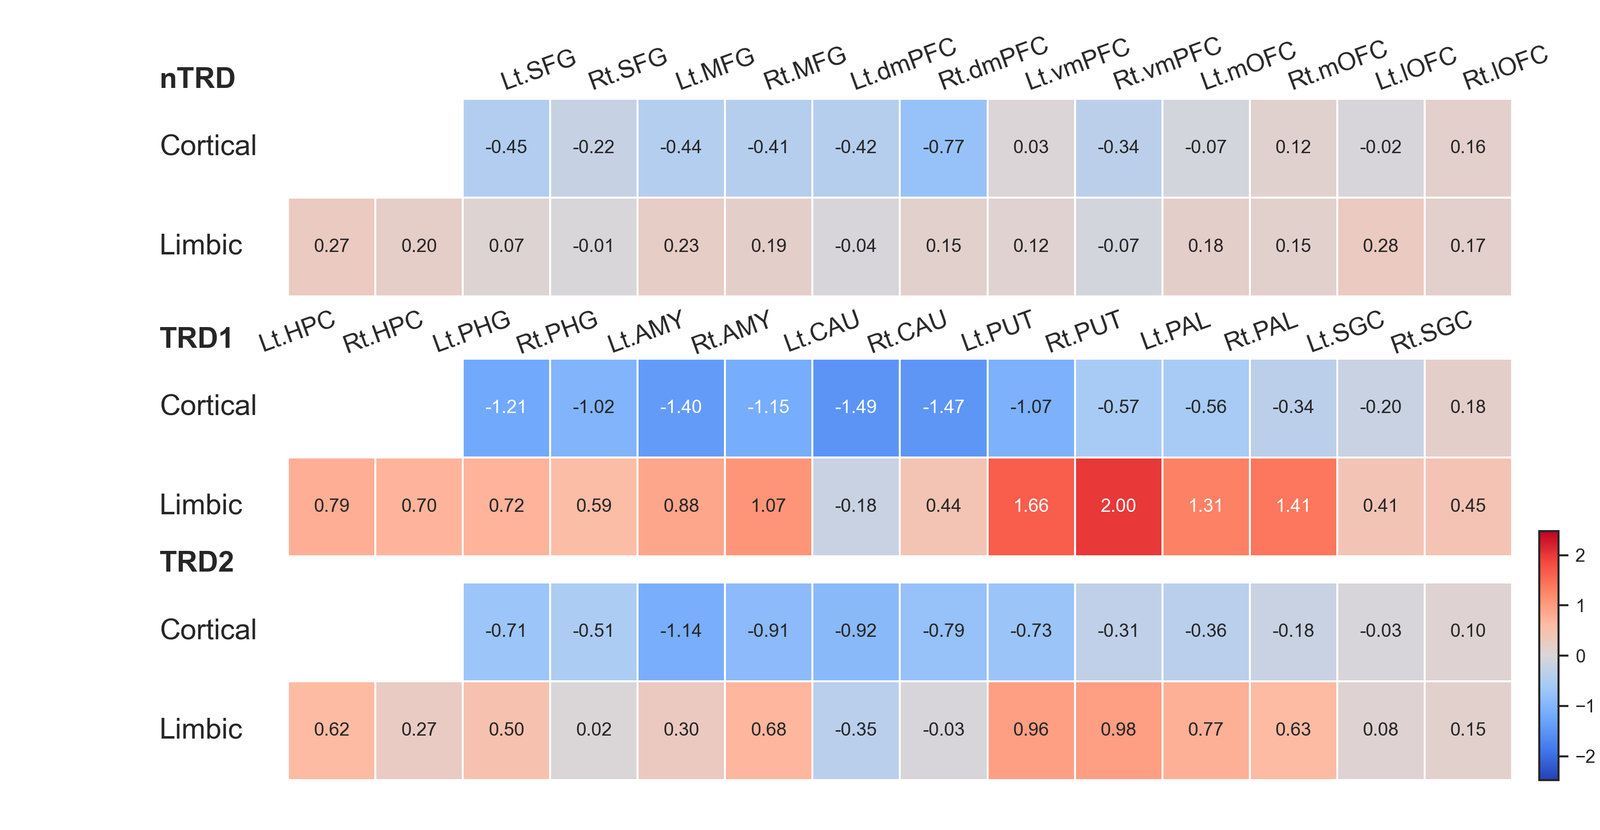

**`outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_corticolimbic12x14_heatmap.png`**

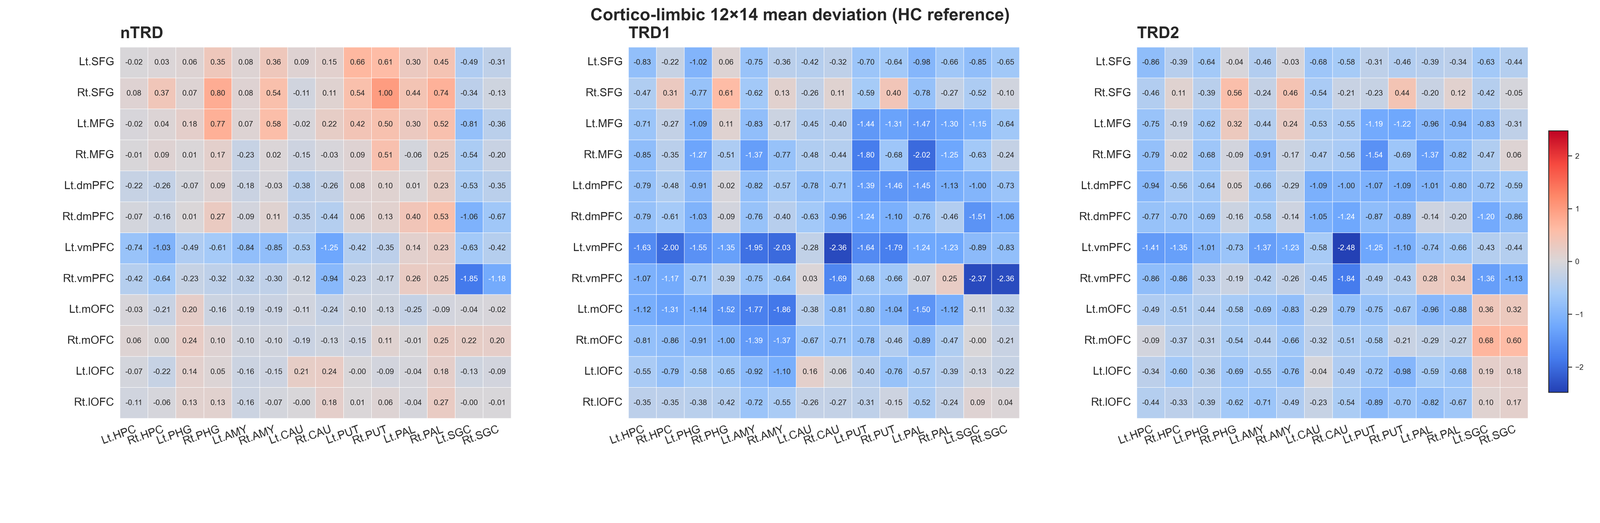

**`outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_age_sex_adjusted_MwC_26ROI_strip_heatmap.png`**

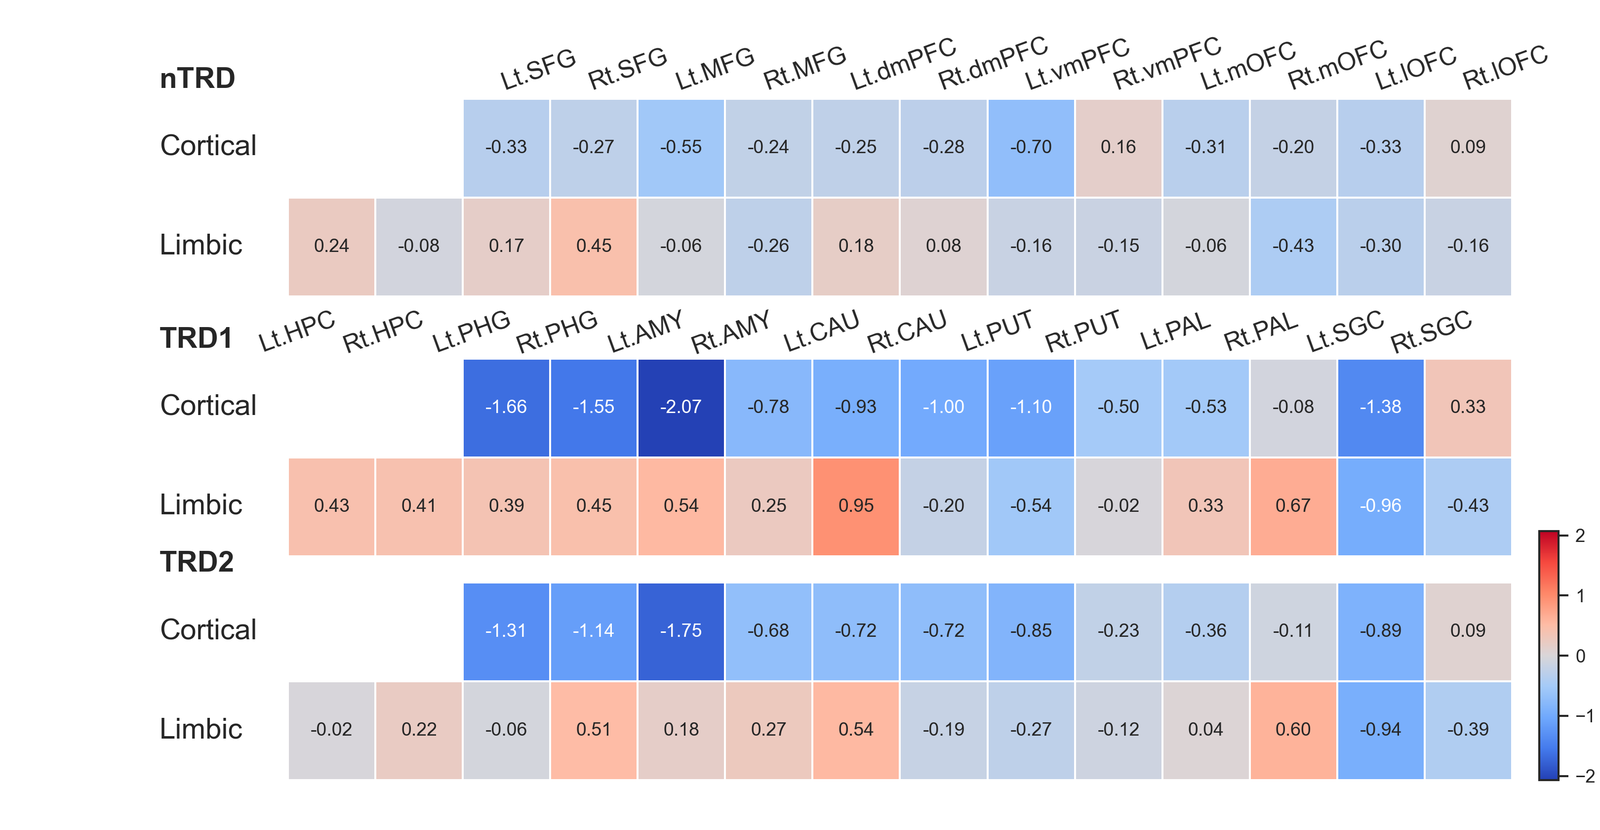

**`outputs/main_analyses/04_figures/corticolimbic_circular_summary.png`**

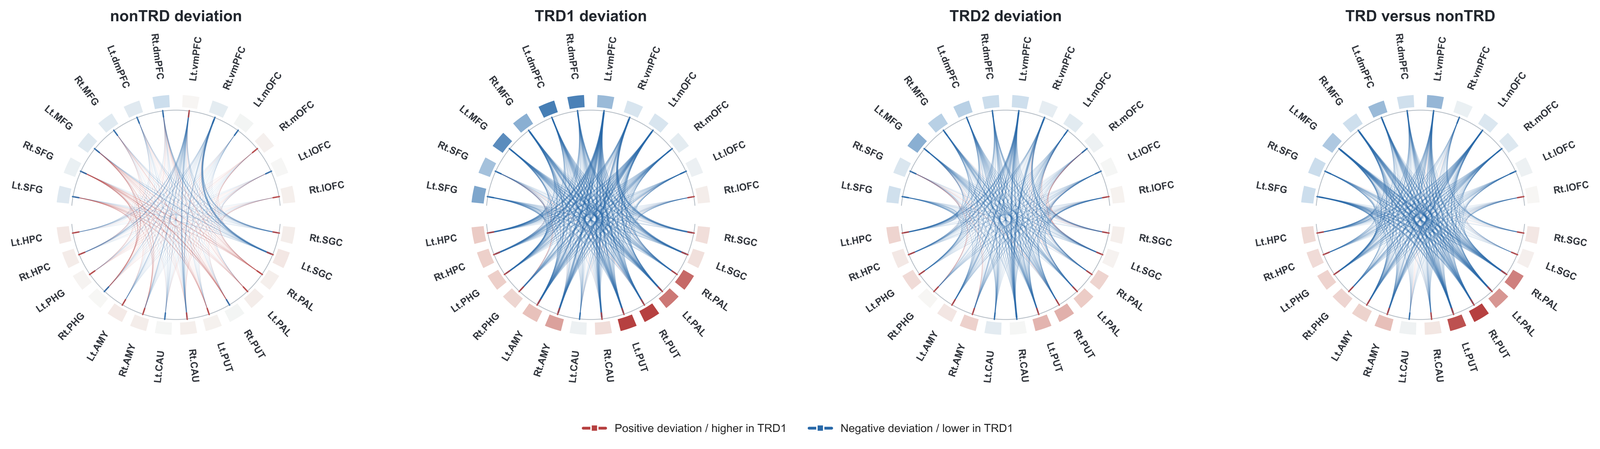

**`outputs/main_analyses/04_figures/TRD2_prepost_raincloud.png`**

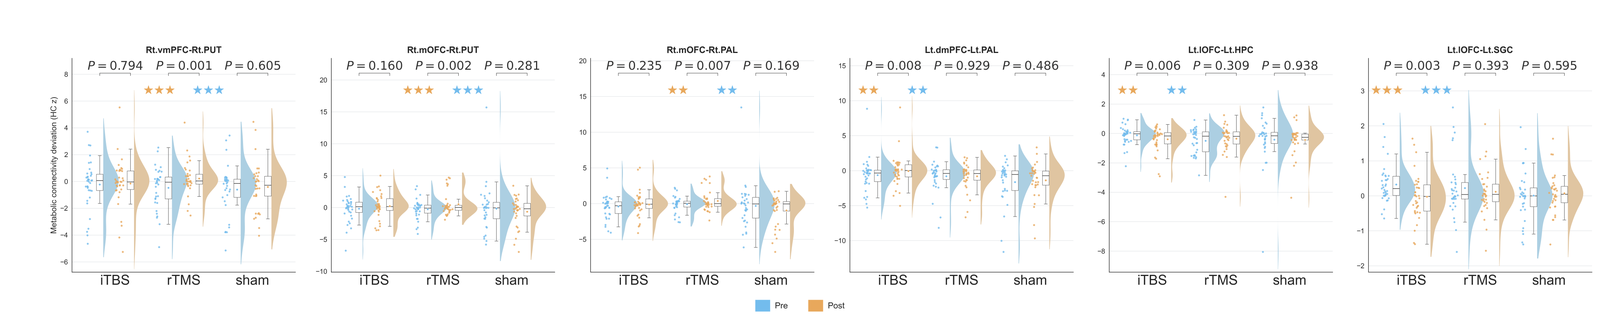

**`outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.png`**

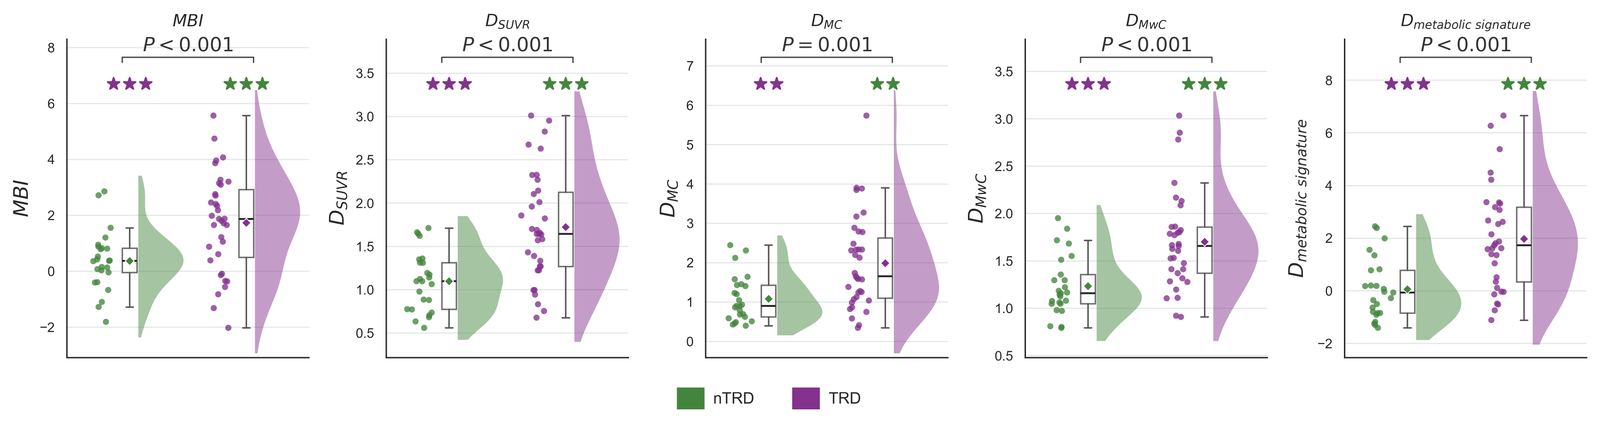

In [17]:
from io import BytesIO
import json as _preview_json
import pandas as _preview_pd
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, Markdown, display

_inline_table_specs = [{'title': 'Integrated analysis summary', 'path': 'outputs/main_analyses/all_reported_results.xlsx', 'sheet': 'summary', 'max_rows': 30}, {'title': 'TRD1-TRD2 spatial replication', 'path': 'outputs/main_analyses/03_TRD1_TRD2_spatial_correlation/spatial_correlation_summary.csv'}, {'title': 'Longitudinal features used for figures (paired p < .01)', 'path': 'outputs/main_analyses/04_figures/TRD2_prepost_raincloud_data.xlsx', 'sheet': 'paired_tests'}, {'title': 'Five indexes: nTRD versus TRD', 'path': 'outputs/main_analyses/10_metabolic_signature_five_metrics/TRD1_vs_nonTRD_five_metrics.xlsx', 'sheet': 'all_five_metrics'}]
_inline_figure_paths = ['outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_regional26_strip_heatmap.png', 'outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_corticolimbic12x14_heatmap.png', 'outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_age_sex_adjusted_MwC_26ROI_strip_heatmap.png', 'outputs/main_analyses/04_figures/corticolimbic_circular_summary.png', 'outputs/main_analyses/04_figures/TRD2_prepost_raincloud.png', 'outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.png']

display(Markdown("### Key tables"))
for _table_spec in _inline_table_specs:
    _relative_table = _table_spec["path"]
    _table_path = _repo / _relative_table
    if not _table_path.is_file():
        raise FileNotFoundError(_table_path)
    if _table_path.suffix.lower() == ".csv":
        _preview_table = _preview_pd.read_csv(_table_path)
    elif _table_path.suffix.lower() in {".xlsx", ".xls"}:
        _preview_table = _preview_pd.read_excel(
            _table_path, sheet_name=_table_spec.get("sheet", 0)
        )
    elif _table_path.suffix.lower() == ".json":
        _payload = _preview_json.loads(_table_path.read_text(encoding="utf-8"))
        _checks = _payload.get("checks", _payload)
        _preview_table = _preview_pd.DataFrame(
            {"item": list(_checks), "value": list(_checks.values())}
        ) if isinstance(_checks, dict) else _preview_pd.json_normalize(_payload)
    else:
        raise ValueError(f"Unsupported table format: {_table_path.suffix}")
    if _table_spec.get("query"):
        _preview_table = _preview_table.query(_table_spec["query"]).reset_index(drop=True)
    _max_rows = int(_table_spec.get("max_rows", 40))
    display(Markdown(
        f"**{_table_spec['title']}**  \n"
        f"`{_relative_table}` — {len(_preview_table)} rows × {len(_preview_table.columns)} columns"
    ))
    with _preview_pd.option_context("display.max_columns", 40, "display.max_colwidth", 60):
        display(_preview_table.head(_max_rows))

if _inline_figure_paths:
    display(Markdown("### Figures"))
for _relative_figure in _inline_figure_paths:
    _figure_path = _repo / _relative_figure
    if not _figure_path.is_file():
        raise FileNotFoundError(_figure_path)
    with PILImage.open(_figure_path) as _source_image:
        _preview_image = _source_image.convert("RGB")
        _preview_image.thumbnail((1600, 1200), PILImage.Resampling.LANCZOS)
        _preview_buffer = BytesIO()
        _preview_image.save(_preview_buffer, format="PNG", optimize=True)
    display(Markdown(f"**`{_relative_figure}`**"))
    display(NotebookImage(data=_preview_buffer.getvalue(), format="png"))
